In [4]:
import pandas as pd
import glob

# List of CSV files you want to process
af_csv_files = glob.glob('mimic_perform_af_*.csv')
non_af_csv_files = glob.glob('mimic_perform_non_af_*.csv')

# Initialize an empty list to store DataFrames
data_frames = []

# Initialize a variable to store the "Time" row (since it's consistent across files)
time_row = None

# Iterate through the AF CSV files
for csv_file in af_csv_files:
    # Read the CSV file
    df = pd.read_csv(csv_file)


    # Drop rows containing NaN values in the "PPG" column
    df.dropna(subset=['PPG'], inplace=True)

    # Extract the "PPG" columns
    ppg_columns = df[['PPG']]

    # Transpose the DataFrame to convert columns to rows
    transposed_data = ppg_columns.T

    # Append the transposed data to the list of DataFrames
    data_frames.append(transposed_data)

    # Store the "Time" row from the first DataFrame (since it's consistent across files)
    if time_row is None:
        time_row = df[['Time']].T

    # Create a "results" column with value 0 for AF data
    transposed_data['results'] = 0

# Iterate through the non-AF CSV files
for csv_file in non_af_csv_files:
    # Read the CSV file
    df = pd.read_csv(csv_file)

    # Drop rows containing NaN values in the "PPG" column
    df.dropna(subset=['PPG'], inplace=True)

    # Extract the "PPG" columns
    ppg_columns = df[['PPG']]

    # Transpose the DataFrame to convert columns to rows
    transposed_data = ppg_columns.T

    # Append the transposed data to the list of DataFrames
    data_frames.append(transposed_data)

    # Store the "Time" row from the first DataFrame (since it's consistent across files)
    if time_row is None:
        time_row = df[['Time']].T

    # Create a "results" column with value 1 for non-AF data
    transposed_data['results'] = 1

# Concatenate the DataFrames in the list, including the "Time" row at the top
combined_data = pd.concat([time_row] + data_frames, ignore_index=True)

# Define the output CSV file path
output_csv_file = 'output5.csv'

# Save the combined data to a new CSV file
combined_data.to_csv(output_csv_file, index=False)


In [5]:
data = pd.read_csv('output5.csv')
data = data.dropna()
data.head(20)

,0,1,2,3,4,5,6,7,8,9,...,149992,149993,149994,149995,149996,149997,149998,149999,150000,results
1,0.961877,0.918866,0.868035,0.817204,0.785924,0.765396,0.740958,0.718475,0.702835,0.695015,...,0.278592,0.276637,0.275660,0.275660,0.276637,0.279570,0.286413,0.298143,0.315738,0.0
5,0.558162,0.558162,0.560117,0.563050,0.566960,0.572825,0.580645,0.589443,0.599218,0.608993,...,0.541544,0.536657,0.530792,0.525904,0.521994,0.517107,0.512219,0.508309,0.504399,0.0
6,2.102639,2.076246,2.049853,2.025415,2.000000,1.973607,1.951124,1.931574,1.912023,1.895406,...,2.169110,2.147605,2.125122,2.101662,2.081134,2.061584,2.043011,2.024438,2.005865,0.0
7,1.888563,1.892473,1.898338,1.910068,1.931574,1.963832,2.004888,2.052786,2.104594,2.157380,...,2.466276,2.467253,2.471163,2.478006,2.483871,2.488759,2.498534,2.514174,2.535679,0.0
8,2.043988,2.130987,2.213099,2.289345,2.354839,2.409580,2.449658,2.478006,2.501466,2.520039,...,1.664712,1.663734,1.666667,1.674487,1.690127,1.708700,1.732160,1.763441,1.801564,0.0
9,0.537634,0.534702,0.531769,0.528837,0.524927,0.520039,0.515152,0.509286,0.504399,0.500489,...,0.402737,0.400782,0.399804,0.400782,0.401760,0.404692,0.409580,0.416422,0.423265,0.0
10,0.479961,0.477028,0.474096,0.471163,0.469208,0.466276,0.463343,0.460411,0.457478,0.448680,...,0.521017,0.516129,0.511241,0.507331,0.504399,0.502444,0.499511,0.497556,0.494624,0.0
11,1.876833,1.869013,1.860215,1.853372,1.849462,1.847507,1.846530,1.849462,1.859238,1.874878,...,2.048876,2.032258,2.016618,2.000978,1.987292,1.974585,1.961877,1.951124,1.943304,0.0
12,2.152493,2.220919,2.285435,2.343109,2.391007,2.426197,2.449658,2.460411,2.459433,2.446725,...,2.101662,2.022483,1.948192,1.867058,1.786901,1.710655,1.641251,1.580645,1.529814,0.0
13,1.808407,1.804497,1.802542,1.799609,1.796676,1.795699,1.792766,1.791789,1.794721,1.799609,...,2.094819,2.096774,2.089932,2.078201,2.061584,2.039101,2.014663,1.989247,1.968719,0.0


In [6]:
import pandas as pd
import matplotlib.pyplot as plt

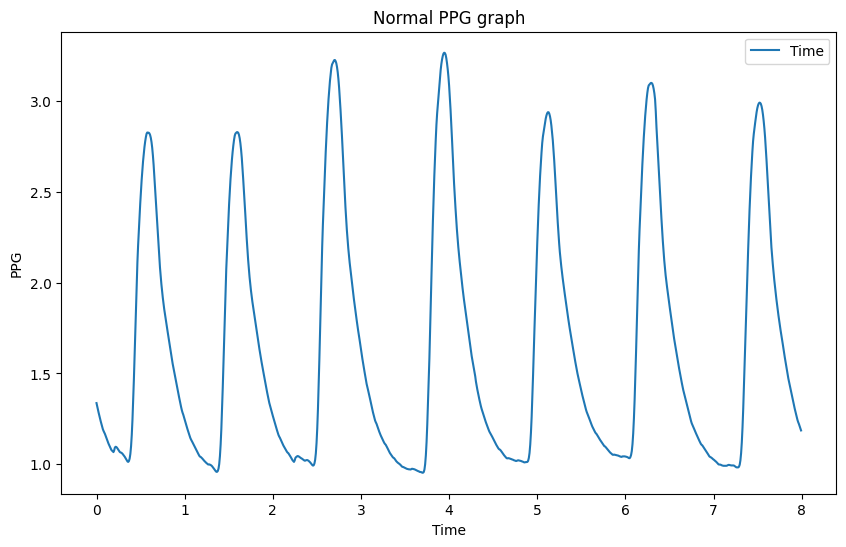

In [7]:
plot_non_af=pd.read_csv('mimic_perform_non_af_002_data.csv')
x_values = plot_non_af['Time'][:1000]
y_values = plot_non_af['PPG'][:1000]

# Create a line graph
plt.figure(figsize=(10, 6))
plt.plot(x_values, y_values, label='Time')

# Customize the plot
plt.title('Normal PPG graph')
plt.xlabel('Time')
plt.ylabel('PPG')
plt.legend()

# Display the plot
plt.show()

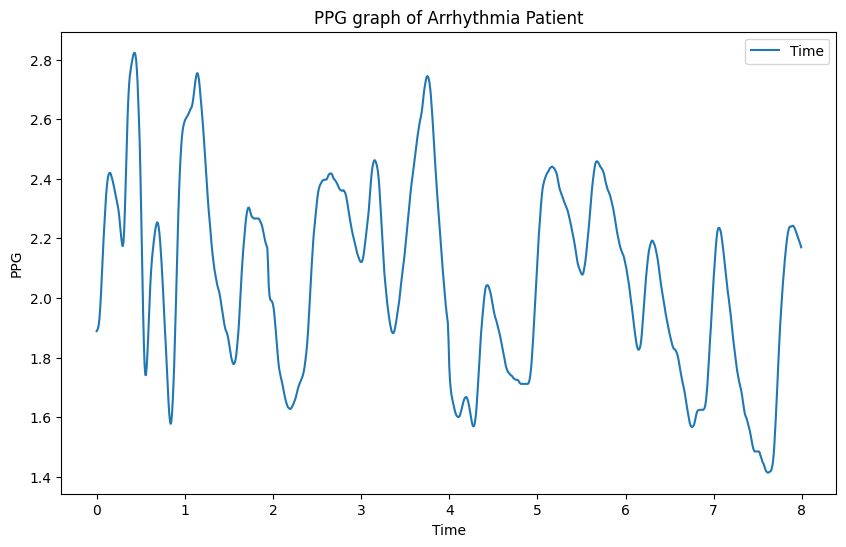

In [8]:
plot_af=pd.read_csv('mimic_perform_af_008_data.csv')
x_values = plot_af['Time'][:1000]
y_values = plot_af['PPG'][:1000]

# Create a line graph
plt.figure(figsize=(10, 6))
plt.plot(x_values, y_values, label='Time')

# Customize the plot
plt.title('PPG graph of Arrhythmia Patient')
plt.xlabel('Time')
plt.ylabel('PPG')
plt.legend()

# Display the plot
plt.show()

In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
import seaborn as sns


In [10]:
# Load your dataset
data = pd.read_csv('output5.csv')

# Remove rows with NaN values in the input features (X)
data = data.dropna()

accuracy = 0
while (accuracy<=0.93):
    # Split the dataset into features (X) and target (y)
    X = data.drop('results', axis=1)
    # Features are the PPG values for 1200 seconds
    y = data['results']
    # Split the data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.6, random_state=21)

    # Initialize and train
    model = tree.DecisionTreeClassifier()
    model.fit(X_train, y_train)

    # Make predictions on the test set
    y_pred = model.predict(X_test)

    # Calculate the accuracy of the model
    accuracy = accuracy_score(y_test, y_pred)


print("Accuracy Achieved: {:.2f}%".format(accuracy * 100))



Accuracy Achieved: 94.12%


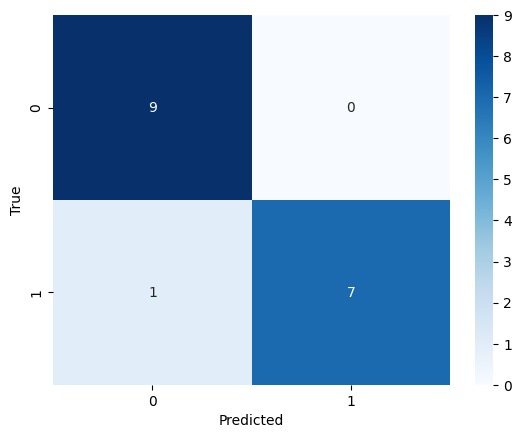

In [11]:
conf_matrix = confusion_matrix(y_test, y_pred)


sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()